# Principal Angle Analysis

Two experiments using the same fixed sample of 1000 rollouts.

- Experiment 1 uses the true correct and incorrect labels.
- Experiment 2 repeatedly replaces those labels with random disjoint groups of 667 and 333 rollouts.

Each rollout representation uses the full reasoning trace before the answer boundary. The class/group matrices are centered before the rank-five subspaces are computed.


## Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean")
RAW_DIR = ROOT / "full" / "raw_layer_outputs"
RECORDS_DIR = ROOT / "full" / "records"

# OLD_OUT_DIR = ROOT / "principal_angle_rank_sweep_r1_r5_1000"
# OLD_SAMPLE_CSV = OLD_OUT_DIR / "sampled_1000_rollouts.csv"

# OUT_DIR = ROOT / "principal_angles_full_reasoning_centered_rank5_control"
# OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = ROOT / "principal_angles_full_reasoning_rank5_control_1000iters"
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_ROLLOUTS = 1000
SAMPLE_SEED = 42
RANK = 5

# CONTROL_A_SIZE = 667
# CONTROL_B_SIZE = 333
N_CONTROL_ITERATIONS = 1000
CONTROL_SEED = 123

assert RAW_DIR.exists(), RAW_DIR
assert RECORDS_DIR.exists(), RECORDS_DIR
# assert CONTROL_A_SIZE + CONTROL_B_SIZE == N_ROLLOUTS


Mounted at /content/drive


## Load the fixed sample

In [2]:
# # Build a record lookup once.
# record_lookup = {}

# for record_path in sorted(RECORDS_DIR.glob("*.json")):
#     with open(record_path, "r", encoding="utf-8") as f:
#         rec = json.load(f)

#     if "sample_id" not in rec or "rollout_id" not in rec:
#         continue

#     lookup_key = (
#         str(rec["sample_id"]),
#         int(rec["rollout_id"]),
#     )
#     record_lookup[lookup_key] = rec


# # Prefer the exact CSV written by the original notebook.
# # If it is unavailable, reconstruct the exact original sampling procedure.
# if OLD_SAMPLE_CSV.exists():
#     sampled = pd.read_csv(OLD_SAMPLE_CSV)
#     sampled["sample_id"] = sampled["sample_id"].astype(str)
#     sampled["rollout_id"] = sampled["rollout_id"].astype(int)
#     sampled["correct"] = sampled["correct"].astype(bool)
#     print("Loaded the original fixed sample.")
# else:
#     rows = []

#     for record_path in sorted(RECORDS_DIR.glob("*.json")):
#         with open(record_path, "r", encoding="utf-8") as f:
#             rec = json.load(f)

#         if rec.get("correct") not in (True, False):
#             continue

#         phase_ranges = rec.get("phase_ranges")
#         if not isinstance(phase_ranges, dict) or "early" not in phase_ranges:
#             continue

#         start, end = map(int, phase_ranges["early"])
#         if end <= start:
#             continue

#         key = f"{rec['sample_id']}_r{int(rec['rollout_id']):02d}"
#         npz_path = RAW_DIR / f"{key}.npz"

#         if not npz_path.exists():
#             continue

#         rows.append({
#             "key": key,
#             "sample_id": str(rec["sample_id"]),
#             "rollout_id": int(rec["rollout_id"]),
#             "correct": bool(rec["correct"]),
#             "npz_path": str(npz_path),
#         })

#     eligible = pd.DataFrame(rows)

#     if len(eligible) < N_ROLLOUTS:
#         raise RuntimeError(
#             f"Only {len(eligible)} eligible rollouts found."
#         )

#     sampled = (
#         eligible
#         .sample(n=N_ROLLOUTS, random_state=SAMPLE_SEED)
#         .reset_index(drop=True)
#     )

#     print("Reconstructed the original fixed sample.")


# # Keep only the fields needed here and rebuild paths consistently.
# fixed_rows = []

# for _, row in sampled.iterrows():
#     sample_id = str(row["sample_id"])
#     rollout_id = int(row["rollout_id"])

#     rec = record_lookup.get((sample_id, rollout_id))
#     if rec is None:
#         raise KeyError(
#             f"Missing record for {sample_id}, rollout {rollout_id}"
#         )

#     key = f"{sample_id}_r{rollout_id:02d}"
#     npz_path = RAW_DIR / f"{key}.npz"

#     if not npz_path.exists():
#         raise FileNotFoundError(npz_path)

#     # Full reasoning trace: generated-token start through the start
#     # of the boxed answer. Fall back to the end of the phase ranges.
#     if rec.get("boxed_token_start") is not None:
#         reasoning_end = int(rec["boxed_token_start"])
#     else:
#         phase_ranges = rec.get("phase_ranges", {})
#         valid_ranges = [
#             tuple(map(int, phase_ranges[name]))
#             for name in ("early", "middle", "late")
#             if name in phase_ranges
#         ]

#         if not valid_ranges:
#             raise KeyError(
#                 f"No answer boundary or phase ranges for {key}"
#             )

#         reasoning_end = max(end for _, end in valid_ranges)

#     if reasoning_end <= 0:
#         raise ValueError(f"Invalid reasoning boundary for {key}")

#     fixed_rows.append({
#         "key": key,
#         "sample_id": sample_id,
#         "rollout_id": rollout_id,
#         "correct": bool(rec["correct"]),
#         "reasoning_start": 0,
#         "reasoning_end": reasoning_end,
#         "npz_path": str(npz_path),
#     })

# fixed = pd.DataFrame(fixed_rows).reset_index(drop=True)

# if len(fixed) != N_ROLLOUTS:
#     raise RuntimeError(
#         f"Expected exactly {N_ROLLOUTS} rollouts, found {len(fixed)}."
#     )

# fixed.to_csv(
#     OUT_DIR / "fixed_1000_rollouts.csv",
#     index=False,
# )

# print("Rollouts:", len(fixed))
# print(
#     fixed["correct"]
#     .value_counts()
#     .rename(index={True: "Correct", False: "Incorrect"})
# )


In [3]:
# # Randomly sample 1000 valid rollouts directly from Drive

# N_ROLLOUTS = 1000
# SAMPLE_SEED = 42

# rows = []

# for record_path in sorted(RECORDS_DIR.glob("*.json")):

#     with open(record_path, "r", encoding="utf-8") as f:
#         rec = json.load(f)

#     # Need a correctness label
#     if rec.get("correct") not in (True, False):
#         continue

#     if "sample_id" not in rec or "rollout_id" not in rec:
#         continue

#     sample_id = str(rec["sample_id"])
#     rollout_id = int(rec["rollout_id"])

#     key = f"{sample_id}_r{rollout_id:02d}"
#     npz_path = RAW_DIR / f"{key}.npz"

#     if not npz_path.exists():
#         continue

#     # Full reasoning trace ends immediately before answer tokens
#     if rec.get("boxed_token_start") is not None:

#         reasoning_end = int(rec["boxed_token_start"])

#     else:

#         # Fallback: use end of late reasoning phase
#         phase_ranges = rec.get("phase_ranges", {})

#         valid_ranges = [
#             tuple(map(int, phase_ranges[name]))
#             for name in ("early", "middle", "late")
#             if name in phase_ranges
#         ]

#         if not valid_ranges:
#             continue

#         reasoning_end = max(
#             end for _, end in valid_ranges
#         )

#     if reasoning_end <= 0:
#         continue

#     rows.append({
#         "key": key,
#         "sample_id": sample_id,
#         "rollout_id": rollout_id,
#         "correct": bool(rec["correct"]),
#         "reasoning_start": 0,
#         "reasoning_end": reasoning_end,
#         "npz_path": str(npz_path),
#     })


# eligible = pd.DataFrame(rows)

# print("Eligible rollouts:", len(eligible))

# if len(eligible) < N_ROLLOUTS:
#     raise RuntimeError(
#         f"Only {len(eligible)} valid rollouts found."
#     )


# # Random sample directly from all valid Drive rollouts
# fixed = (
#     eligible
#     .sample(
#         n=N_ROLLOUTS,
#         random_state=SAMPLE_SEED,
#     )
#     .reset_index(drop=True)
# )


# fixed.to_csv(
#     OUT_DIR / "random_1000_rollouts.csv",
#     index=False,
# )


# print("Selected rollouts:", len(fixed))

# print(
#     fixed["correct"]
#     .value_counts()
#     .rename({
#         True: "Correct",
#         False: "Incorrect",
#     })
# )

In [4]:
# N_ROLLOUTS = 1000
# SAMPLE_SEED = 42

# rows = []

# for record_path in sorted(RECORDS_DIR.glob("*.json")):

#     with open(record_path, "r", encoding="utf-8") as f:
#         rec = json.load(f)

#     if rec.get("correct") not in (True, False):
#         continue

#     if rec.get("boxed_token_start") is None:
#         continue

#     sample_id = str(rec["sample_id"])
#     rollout_id = int(rec["rollout_id"])

#     key = f"{sample_id}_r{rollout_id:02d}"
#     npz_path = RAW_DIR / f"{key}.npz"

#     if not npz_path.exists():
#         continue

#     rows.append({
#         "key": key,
#         "sample_id": sample_id,
#         "rollout_id": rollout_id,
#         "correct": bool(rec["correct"]),
#         "reasoning_start": 0,
#         "reasoning_end": int(rec["boxed_token_start"]),
#         "npz_path": str(npz_path),
#     })

# eligible = pd.DataFrame(rows)

# print("Eligible rollouts:", len(eligible))

# fixed = (
#     eligible
#     .sample(n=1000, random_state=SAMPLE_SEED)
#     .reset_index(drop=True)
# )

# fixed.to_csv(
#     OUT_DIR / "sampled_1000_rollouts.csv",
#     index=False,
# )

# print("Sampled:", len(fixed))
# print(fixed["correct"].value_counts())

# # print("Sampled:", len(fixed))
# # print(fixed["correct"].value_counts())

In [5]:
N_ROLLOUTS = 1000
SAMPLE_SEED = 42

METADATA_PATH = (
    ROOT
    / "analysis_cache_spectral"
    / "rollout_metadata.parquet"
)

metadata = pd.read_parquet(METADATA_PATH).copy()

# Make key/path consistent with the current Drive mount
if "key" not in metadata.columns:
    metadata["key"] = metadata["raw_path"].map(
        lambda x: Path(str(x)).stem
    )

metadata["npz_path"] = metadata["key"].map(
    lambda key: str(RAW_DIR / f"{key}.npz")
)

# Keep resolved correct/incorrect rollouts
eligible = metadata[
    metadata["correct"].isin([True, False])
].copy()

# Need a usable reasoning boundary
eligible = eligible[
    eligible["boxed_token_start"].notna()
].copy()

# Make sure raw NPZ exists
eligible = eligible[
    eligible["npz_path"].map(lambda p: Path(p).exists())
].copy()

eligible["reasoning_start"] = 0
eligible["reasoning_end"] = (
    eligible["boxed_token_start"].astype(int)
)

print("Eligible rollouts:", len(eligible))

assert len(eligible) >= N_ROLLOUTS

fixed = (
    eligible
    .sample(
        n=N_ROLLOUTS,
        replace=False,
        random_state=SAMPLE_SEED,
    )
    .reset_index(drop=True)
)

fixed.to_csv(
    OUT_DIR / "sampled_1000_rollouts.csv",
    index=False,
)

print("Sampled:", len(fixed))
print(fixed["correct"].value_counts())

Eligible rollouts: 9780
Sampled: 1000
correct
True     637
False    363
Name: count, dtype: int64


In [6]:
# correct_len = len(fixed["correct"])
# incorrect_len = len(fixed["incorrect"]

correct_len = int(fixed["correct"].sum())
incorrect_len = int((~fixed["correct"].astype(bool)).sum())

assert correct_len + incorrect_len == N_ROLLOUTS

print("Correct:", correct_len)
print("Incorrect:", incorrect_len)

Correct: 637
Incorrect: 363


## Build reasoning representations

In [7]:
def get_reasoning_representation(npz_path, start, end):
    with np.load(npz_path, allow_pickle=False) as z:
        H_all = np.asarray(
            z["causal_hidden_states"],
            dtype=np.float32,
        )

    if end > H_all.shape[1]:
        raise ValueError(
            f"Reasoning boundary {end} exceeds hidden-state length "
            f"{H_all.shape[1]} in {npz_path}"
        )

    H = H_all[:, start:end, :]

    if H.shape[1] == 0:
        raise ValueError(f"Empty reasoning trace in {npz_path}")

    # Same rollout representation construction as the original notebook:
    # tokenwise L2 normalization followed by mean pooling.
    norms = np.linalg.norm(H, axis=-1, keepdims=True)
    H_unit = H / np.clip(norms, 1e-12, None)

    return H_unit.mean(axis=1).astype(np.float32)


representations = []

for i, row in fixed.iterrows():
    X = get_reasoning_representation(
        row["npz_path"],
        int(row["reasoning_start"]),
        int(row["reasoning_end"]),
    )
    representations.append(X)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(fixed)}")

R = np.stack(representations, axis=0)

print("Representation tensor:", R.shape)
print("Layout: rollouts, layers, hidden dimension")


Processed 100/1000
Processed 200/1000
Processed 300/1000
Processed 400/1000
Processed 500/1000
Processed 600/1000
Processed 700/1000
Processed 800/1000
Processed 900/1000
Processed 1000/1000
Representation tensor: (1000, 26, 1152)
Layout: rollouts, layers, hidden dimension


## Principal angle utilities

In [8]:
def center_matrix(X):
    return X - X.mean(axis=0, keepdims=True)


def top_rank_basis(X, rank=RANK):
    X_centered = center_matrix(X)

    _, _, Vh = np.linalg.svd(
        X_centered,
        full_matrices=False,
    )

    return Vh[:rank].T


def principal_angles(QA, QB):
    overlap = QA.T @ QB

    singular_values = np.linalg.svd(
        overlap,
        compute_uv=False,
    )

    singular_values = np.clip(
        singular_values,
        0.0,
        1.0,
    )

    # No additional sorting.
    angles = np.degrees(
        np.arccos(singular_values)
    )

    return singular_values, angles


def compute_rank_five_angles(group_a, group_b):
    rows = []

    for layer_idx in range(R.shape[1]):
        XA = R[group_a, layer_idx, :]
        XB = R[group_b, layer_idx, :]

        QA = top_rank_basis(XA)
        QB = top_rank_basis(XB)

        singular_values, angles = principal_angles(QA, QB)

        for angle_idx in range(RANK):
            rows.append({
                "model_layer_one_based": layer_idx + 1,
                "principal_angle_index": angle_idx + 1,
                "overlap_singular_value": float(
                    singular_values[angle_idx]
                ),
                "principal_angle_deg": float(
                    angles[angle_idx]
                ),
            })

    return pd.DataFrame(rows)


def plot_angles(df, title, save_path=None):
    fig, ax = plt.subplots(figsize=(9, 4.8))

    for angle_idx in range(1, RANK + 1):
        curve = (
            df[df["principal_angle_index"] == angle_idx]
            .sort_values("model_layer_one_based")
        )

        ax.plot(
            curve["model_layer_one_based"],
            curve["principal_angle_deg"],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=f"theta {angle_idx}",
        )

    ax.set_xlabel("Model layer")
    ax.set_ylabel("Principal angle (degrees)")
    ax.set_title(title)
    ax.set_ylim(0, 90)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, ncol=5)
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=180,
            bbox_inches="tight",
        )

    plt.show()


## Experiment 1

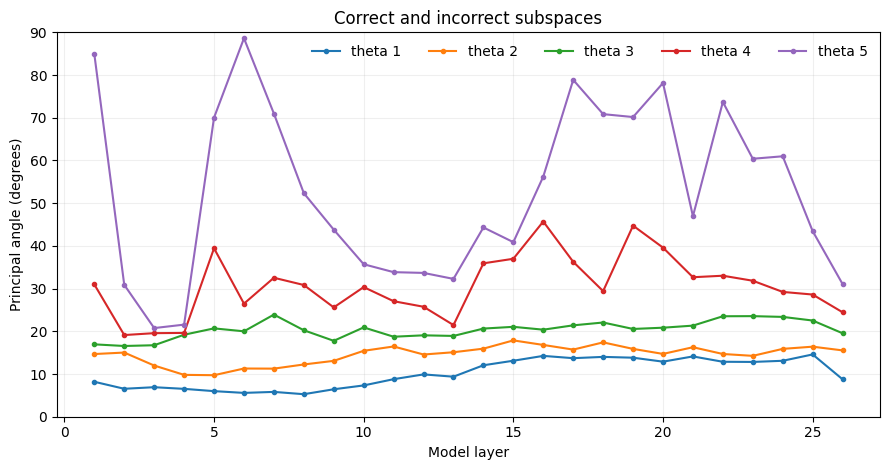

,model_layer_one_based,principal_angle_index,overlap_singular_value,principal_angle_deg
0,1,1,0.989821,8.182061
1,1,2,0.967376,14.675568
2,1,3,0.956587,16.944504
3,1,4,0.857396,30.974548
4,1,5,0.088496,84.922928
5,2,1,0.993485,6.544006
6,2,2,0.965821,15.023287
7,2,3,0.958513,16.561785
8,2,4,0.944825,19.121613
9,2,5,0.858260,30.878248


In [9]:
correct_mask = fixed["correct"].to_numpy(dtype=bool)
incorrect_mask = ~correct_mask

experiment1_df = compute_rank_five_angles(
    correct_mask,
    incorrect_mask,
)

experiment1_df.to_csv(
    OUT_DIR / "experiment1_true_labels_angles.csv",
    index=False,
)

plot_angles(
    experiment1_df,
    title="Correct and incorrect subspaces",
    save_path=OUT_DIR / "experiment1_true_labels_angles.png",
)

display(experiment1_df.head(10))


## Experiment 2

In [10]:
rng = np.random.default_rng(CONTROL_SEED)

control_frames = []

CONTROL_A_SIZE = correct_len
CONTROL_B_SIZE = incorrect_len
for iteration in range(1, N_CONTROL_ITERATIONS + 1):
    permutation = rng.permutation(N_ROLLOUTS)

    group_a_idx = permutation[:CONTROL_A_SIZE]
    group_b_idx = permutation[
        CONTROL_A_SIZE:
        CONTROL_A_SIZE + CONTROL_B_SIZE
    ]

    iteration_df = compute_rank_five_angles(
        group_a_idx,
        group_b_idx,
    )

    iteration_df.insert(
        0,
        "iteration",
        iteration,
    )

    control_frames.append(iteration_df)

    print(
        f"Completed random split "
        f"{iteration}/{N_CONTROL_ITERATIONS}"
    )

control_df = pd.concat(
    control_frames,
    ignore_index=True,
)

control_df.to_csv(
    OUT_DIR / "experiment2_random_split_angles.csv",
    index=False,
)

display(control_df.head(10))


Completed random split 1/1000
Completed random split 2/1000
Completed random split 3/1000
Completed random split 4/1000
Completed random split 5/1000
Completed random split 6/1000
Completed random split 7/1000
Completed random split 8/1000
Completed random split 9/1000
Completed random split 10/1000
Completed random split 11/1000
Completed random split 12/1000
Completed random split 13/1000
Completed random split 14/1000
Completed random split 15/1000
Completed random split 16/1000
Completed random split 17/1000
Completed random split 18/1000
Completed random split 19/1000
Completed random split 20/1000
Completed random split 21/1000
Completed random split 22/1000
Completed random split 23/1000
Completed random split 24/1000
Completed random split 25/1000
Completed random split 26/1000
Completed random split 27/1000
Completed random split 28/1000
Completed random split 29/1000
Completed random split 30/1000
Completed random split 31/1000
Completed random split 32/1000
Completed random 

,iteration,model_layer_one_based,principal_angle_index,overlap_singular_value,principal_angle_deg
0,1,1,1,0.995224,5.601856
1,1,1,2,0.982819,10.636301
2,1,1,3,0.979423,11.643306
3,1,1,4,0.915762,23.685757
4,1,1,5,0.181419,79.547585
5,1,2,1,0.995777,5.267749
6,1,2,2,0.990925,7.724968
7,1,2,3,0.985119,9.896780
8,1,2,4,0.966807,14.803699
9,1,2,5,0.904144,25.291824


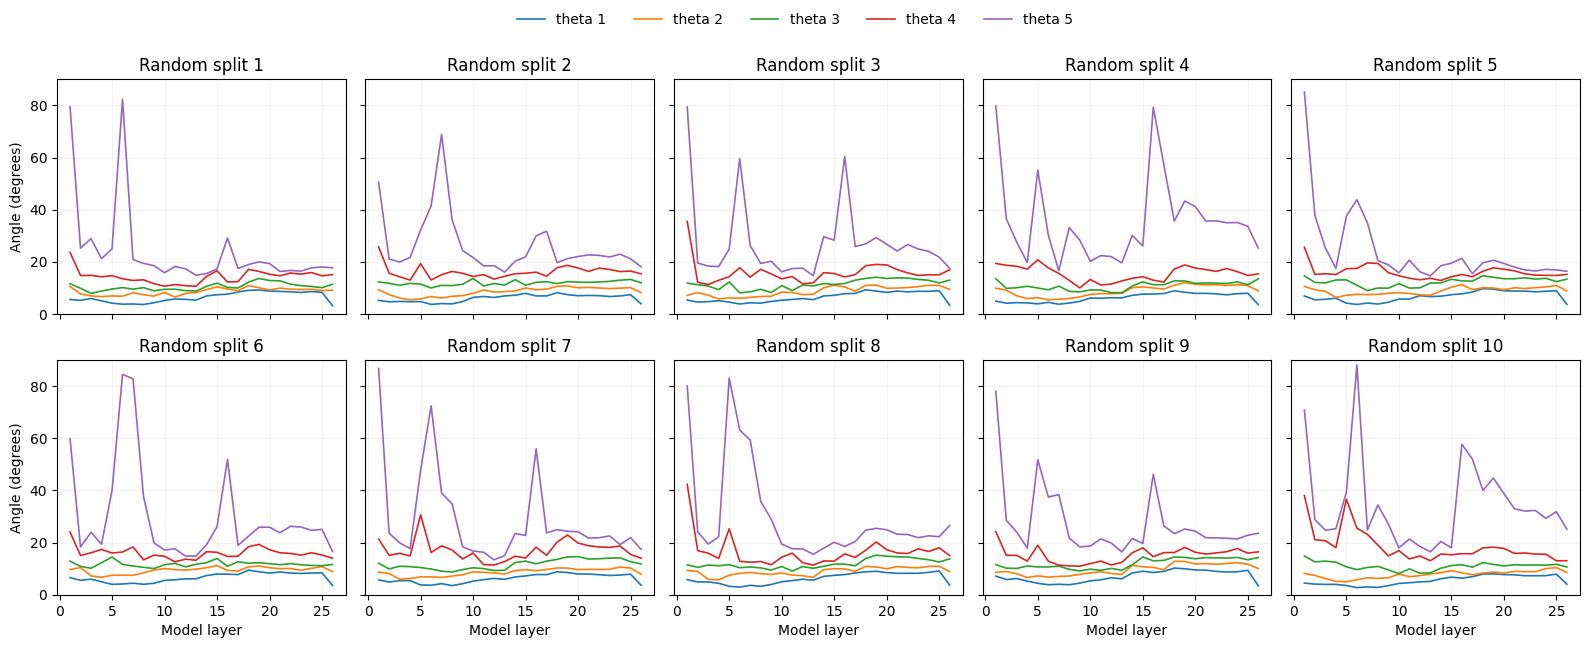

In [11]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(16, 6.5),
    sharex=True,
    sharey=True,
)

for iteration, ax in zip(
    range(1, N_CONTROL_ITERATIONS + 1),
    axes.ravel(),
):
    iteration_df = control_df[
        control_df["iteration"] == iteration
    ]

    for angle_idx in range(1, RANK + 1):
        curve = (
            iteration_df[
                iteration_df["principal_angle_index"] == angle_idx
            ]
            .sort_values("model_layer_one_based")
        )

        ax.plot(
            curve["model_layer_one_based"],
            curve["principal_angle_deg"],
            linewidth=1.2,
            label=f"theta {angle_idx}",
        )

    ax.set_title(f"Random split {iteration}")
    ax.set_ylim(0, 90)
    ax.grid(alpha=0.15)

for ax in axes[-1]:
    ax.set_xlabel("Model layer")

for ax in axes[:, 0]:
    ax.set_ylabel("Angle (degrees)")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
    frameon=False,
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

fig.savefig(
    OUT_DIR / "experiment2_random_split_iterations.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()


## Average control result

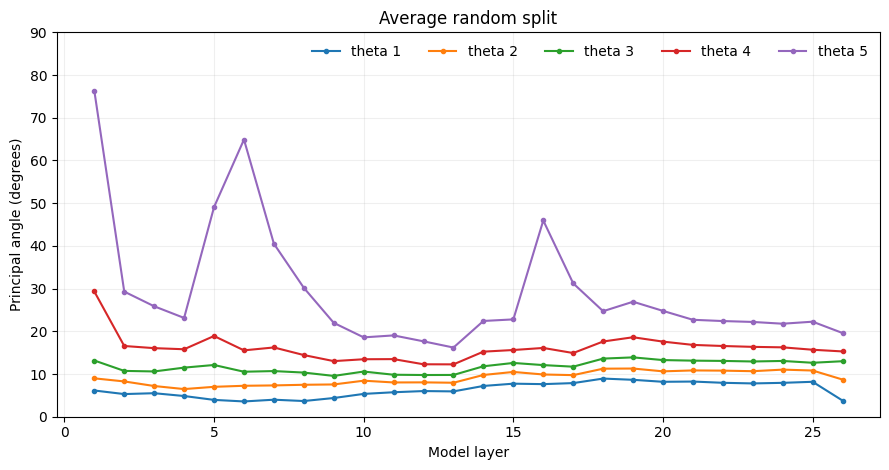

,model_layer_one_based,principal_angle_index,mean_angle_deg,std_angle_deg
0,1,1,6.139313,0.671827
1,1,2,8.986031,0.986863
2,1,3,13.163297,1.778232
3,1,4,29.319940,7.560989
4,1,5,76.323062,9.970516
5,2,1,5.303579,0.597675
6,2,2,8.261512,0.875005
7,2,3,10.727781,1.254586
8,2,4,16.560210,2.799795
9,2,5,29.295071,8.021882


Saved results to:
/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/principal_angles_full_reasoning_rank5_control_1000iters


In [12]:
control_mean_df = (
    control_df
    .groupby(
        [
            "model_layer_one_based",
            "principal_angle_index",
        ],
        as_index=False,
    )
    .agg(
        mean_angle_deg=(
            "principal_angle_deg",
            "mean",
        ),
        std_angle_deg=(
            "principal_angle_deg",
            "std",
        ),
    )
)

control_mean_df.to_csv(
    OUT_DIR / "experiment2_random_split_mean_angles.csv",
    index=False,
)

plot_df = control_mean_df.rename(
    columns={
        "mean_angle_deg": "principal_angle_deg"
    }
)

plot_angles(
    plot_df,
    title="Average random split",
    save_path=OUT_DIR / "experiment2_random_split_mean_angles.png",
)

display(control_mean_df.head(10))

print("Saved results to:")
print(OUT_DIR)


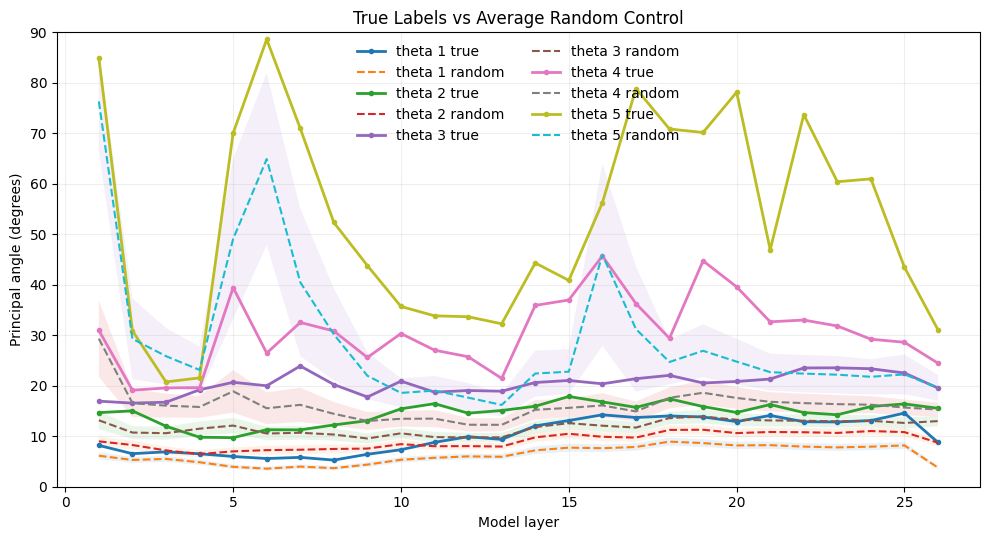

In [13]:
# Compare Experiment 1 with average random control

fig, ax = plt.subplots(figsize=(10, 5.5))

for angle_idx in range(1, RANK + 1):

    exp_curve = (
        experiment1_df[
            experiment1_df["principal_angle_index"] == angle_idx
        ]
        .sort_values("model_layer_one_based")
    )

    ctrl_curve = (
        control_mean_df[
            control_mean_df["principal_angle_index"] == angle_idx
        ]
        .sort_values("model_layer_one_based")
    )

    x = ctrl_curve["model_layer_one_based"].to_numpy()
    mean = ctrl_curve["mean_angle_deg"].to_numpy()
    std = ctrl_curve["std_angle_deg"].to_numpy()

    # True correct vs incorrect result
    ax.plot(
        exp_curve["model_layer_one_based"],
        exp_curve["principal_angle_deg"],
        linewidth=2,
        marker="o",
        markersize=3,
        label=f"theta {angle_idx} true",
    )

    # Average random split
    ax.plot(
        x,
        mean,
        linewidth=1.5,
        linestyle="--",
        label=f"theta {angle_idx} random",
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.10,
    )

ax.set_xlabel("Model layer")
ax.set_ylabel("Principal angle (degrees)")
ax.set_title("True Labels vs Average Random Control")
ax.set_ylim(0, 90)
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

fig.savefig(
    OUT_DIR / "experiment1_vs_random_control.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [14]:
# Table: Experiment 1 vs average random control

comparison_table = (
    experiment1_df[
        [
            "model_layer_one_based",
            "principal_angle_index",
            "principal_angle_deg",
        ]
    ]
    .merge(
        control_mean_df[
            [
                "model_layer_one_based",
                "principal_angle_index",
                "mean_angle_deg",
                "std_angle_deg",
            ]
        ],
        on=[
            "model_layer_one_based",
            "principal_angle_index",
        ],
        how="left",
    )
    .rename(columns={
        "principal_angle_deg": "true_angle_deg",
        "mean_angle_deg": "random_mean_deg",
        "std_angle_deg": "random_std_deg",
    })
)

display(comparison_table.round(3))

,model_layer_one_based,principal_angle_index,true_angle_deg,random_mean_deg,random_std_deg
0,1,1,8.182,6.139,0.672
1,1,2,14.676,8.986,0.987
2,1,3,16.945,13.163,1.778
3,1,4,30.975,29.320,7.561
4,1,5,84.923,76.323,9.971
...,...,...,...,...,...
125,26,1,8.761,3.776,0.312
126,26,2,15.530,8.702,0.770
127,26,3,19.541,12.996,1.052
128,26,4,24.455,15.286,1.345


In [15]:
# Experiment 1 > random-control mean?

comparison_bool = (
    experiment1_df[
        [
            "model_layer_one_based",
            "principal_angle_index",
            "principal_angle_deg",
        ]
    ]
    .merge(
        control_mean_df[
            [
                "model_layer_one_based",
                "principal_angle_index",
                "mean_angle_deg",
            ]
        ],
        on=[
            "model_layer_one_based",
            "principal_angle_index",
        ],
    )
)

comparison_bool["exp1_greater_than_random"] = (
    comparison_bool["principal_angle_deg"]
    > comparison_bool["mean_angle_deg"]
)

display(
    comparison_bool[
        [
            "model_layer_one_based",
            "principal_angle_index",
            "principal_angle_deg",
            "mean_angle_deg",
            "exp1_greater_than_random",
        ]
    ]
)

,model_layer_one_based,principal_angle_index,principal_angle_deg,mean_angle_deg,exp1_greater_than_random
0,1,1,8.182061,6.139313,True
1,1,2,14.675568,8.986031,True
2,1,3,16.944504,13.163297,True
3,1,4,30.974548,29.319940,True
4,1,5,84.922928,76.323062,True
...,...,...,...,...,...
125,26,1,8.760692,3.775761,True
126,26,2,15.530196,8.701886,True
127,26,3,19.541319,12.996071,True
128,26,4,24.454796,15.285886,True


In [16]:
comparison_bool["exp1_greater_than_random"].all()

np.False_

In [17]:
comparison_bool["exp1_greater_than_random"].sum(), len(comparison_bool)

(np.int64(128), 130)